In [107]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [108]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier

from sklearn.ensemble import AdaBoostClassifier,GradientBoostingClassifier
from xgboost import XGBClassifier

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score,classification_report,f1_score

In [109]:
df = pd.read_csv("rainfall.csv")
df.head()

,datetime,temp,dew,humidity,sealevelpressure,winddir,solarradiation,windspeed,precipprob,preciptype
0,01-01-2016,28.4,11.9,37.8,1016.4,147.5,216.1,16.6,0,0
1,02-01-2016,26.8,13.0,44.8,1017.2,110.3,215.7,16.6,0,0
2,03-01-2016,25.5,14.6,52.8,1015.7,145.3,221.1,18.4,0,0
3,04-01-2016,26.4,13.1,46.6,1015.3,126.9,216.2,16.6,0,0
4,05-01-2016,27.1,13.5,44.9,1014.4,125.5,208.1,16.6,0,0


In [110]:
def month(date : str):
    return int(date.split("-")[1])

In [111]:
df.insert(0,"month",df["datetime"].apply(month))
df.head()

,month,datetime,temp,dew,humidity,sealevelpressure,winddir,solarradiation,windspeed,precipprob,preciptype
0,1,01-01-2016,28.4,11.9,37.8,1016.4,147.5,216.1,16.6,0,0
1,1,02-01-2016,26.8,13.0,44.8,1017.2,110.3,215.7,16.6,0,0
2,1,03-01-2016,25.5,14.6,52.8,1015.7,145.3,221.1,18.4,0,0
3,1,04-01-2016,26.4,13.1,46.6,1015.3,126.9,216.2,16.6,0,0
4,1,05-01-2016,27.1,13.5,44.9,1014.4,125.5,208.1,16.6,0,0


In [112]:
df.shape

(1781, 11)

In [113]:
df.columns

Index(['month', 'datetime', 'temp', 'dew', 'humidity', 'sealevelpressure',
       'winddir', 'solarradiation', 'windspeed', 'precipprob', 'preciptype'],
      dtype='object')

In [114]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1781 entries, 0 to 1780
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   month             1781 non-null   int64  
 1   datetime          1781 non-null   object 
 2   temp              1781 non-null   float64
 3   dew               1781 non-null   float64
 4   humidity          1781 non-null   float64
 5   sealevelpressure  1781 non-null   float64
 6   winddir           1781 non-null   float64
 7   solarradiation    1781 non-null   float64
 8   windspeed         1781 non-null   float64
 9   precipprob        1781 non-null   int64  
 10  preciptype        1781 non-null   int64  
dtypes: float64(7), int64(3), object(1)
memory usage: 153.2+ KB


In [115]:
df.describe()

,month,temp,dew,humidity,sealevelpressure,winddir,solarradiation,windspeed,precipprob,preciptype
count,1781.000000,1781.000000,1781.000000,1781.000000,1781.000000,1781.000000,1781.000000,1781.000000,1781.000000,1781.000000
mean,6.387984,28.342560,21.644975,69.565974,1008.878046,201.304267,228.169175,22.309882,45.648512,0.456485
std,3.391405,1.960027,4.532065,14.533809,3.706157,47.075559,57.034865,6.360669,49.824275,0.498243
min,1.000000,20.200000,5.000000,28.600000,994.100000,65.600000,52.800000,9.400000,0.000000,0.000000
25%,3.000000,27.200000,18.100000,58.000000,1006.200000,163.700000,194.600000,18.400000,0.000000,0.000000
50%,6.000000,28.500000,23.800000,71.600000,1009.100000,204.500000,232.300000,22.300000,0.000000,0.000000
75%,9.000000,29.700000,25.300000,81.200000,1011.800000,240.900000,274.400000,24.600000,100.000000,1.000000
max,12.000000,32.800000,27.500000,98.200000,1017.400000,316.000000,330.900000,128.100000,100.000000,1.000000


In [116]:
df = df.drop_duplicates()
df.duplicated().sum()

np.int64(0)

In [117]:
df["preciptype"].unique()

array([0, 1])

In [118]:
df["preciptype"].value_counts()

preciptype
0    968
1    813
Name: count, dtype: int64

In [119]:
df.isnull().sum()

month               0
datetime            0
temp                0
dew                 0
humidity            0
sealevelpressure    0
winddir             0
solarradiation      0
windspeed           0
precipprob          0
preciptype          0
dtype: int64

In [120]:
df["precipprob"].unique().sum()

np.int64(100)

In [121]:
df.head()

,month,datetime,temp,dew,humidity,sealevelpressure,winddir,solarradiation,windspeed,precipprob,preciptype
0,1,01-01-2016,28.4,11.9,37.8,1016.4,147.5,216.1,16.6,0,0
1,1,02-01-2016,26.8,13.0,44.8,1017.2,110.3,215.7,16.6,0,0
2,1,03-01-2016,25.5,14.6,52.8,1015.7,145.3,221.1,18.4,0,0
3,1,04-01-2016,26.4,13.1,46.6,1015.3,126.9,216.2,16.6,0,0
4,1,05-01-2016,27.1,13.5,44.9,1014.4,125.5,208.1,16.6,0,0


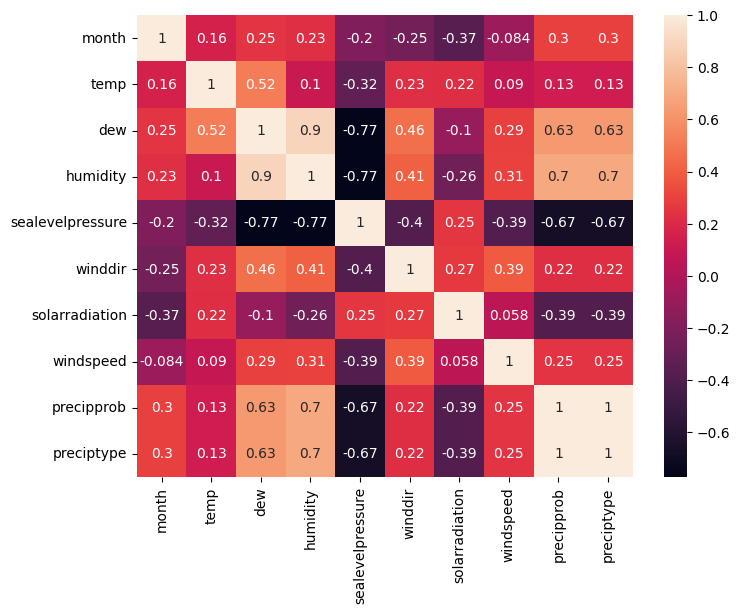

In [122]:
plt.figure(figsize=(8,6))
sns.heatmap(df.corr(numeric_only=True),annot=True)
plt.show()

In [123]:
X = df.drop(["preciptype","datetime"],axis=1)
y = df['preciptype']
X.head()

,month,temp,dew,humidity,sealevelpressure,winddir,solarradiation,windspeed,precipprob
0,1,28.4,11.9,37.8,1016.4,147.5,216.1,16.6,0
1,1,26.8,13.0,44.8,1017.2,110.3,215.7,16.6,0
2,1,25.5,14.6,52.8,1015.7,145.3,221.1,18.4,0
3,1,26.4,13.1,46.6,1015.3,126.9,216.2,16.6,0
4,1,27.1,13.5,44.9,1014.4,125.5,208.1,16.6,0


In [124]:
y.head()

0    0
1    0
2    0
3    0
4    0
Name: preciptype, dtype: int64

In [125]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42,stratify=y)

In [126]:
num_cols = X.select_dtypes("number").columns.tolist()

print(num_cols)

['month', 'temp', 'dew', 'humidity', 'sealevelpressure', 'winddir', 'solarradiation', 'windspeed', 'precipprob']


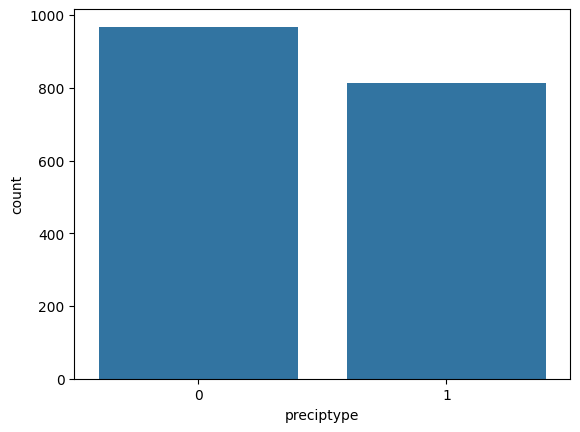

In [127]:
sns.countplot(df,x="preciptype")
plt.show()

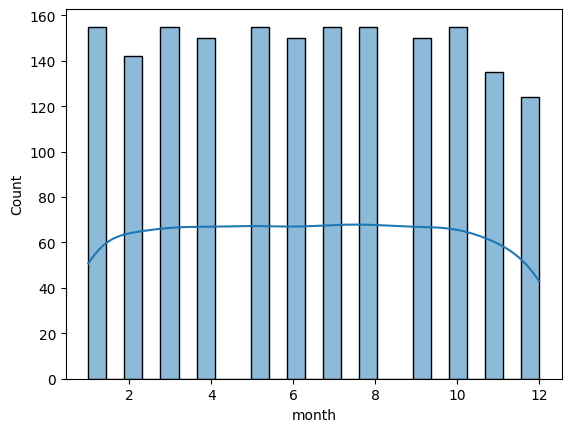

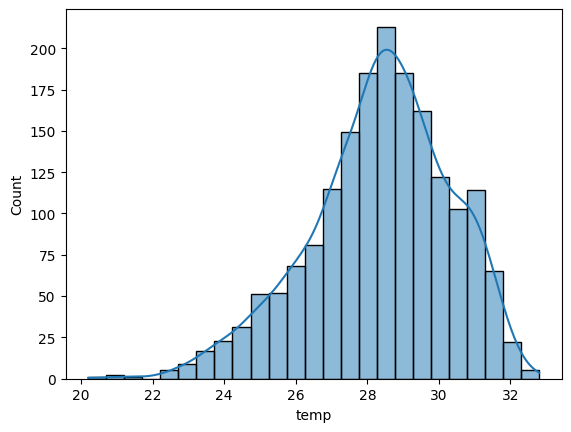

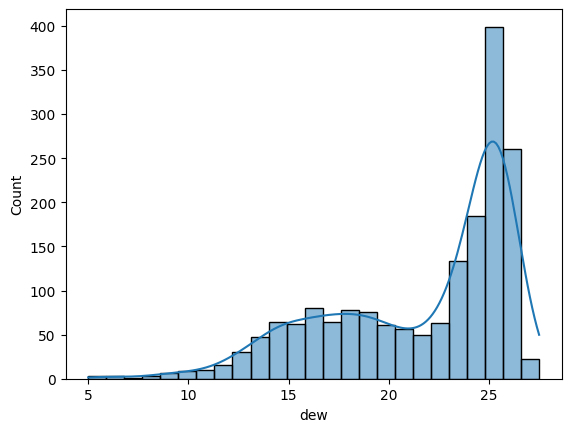

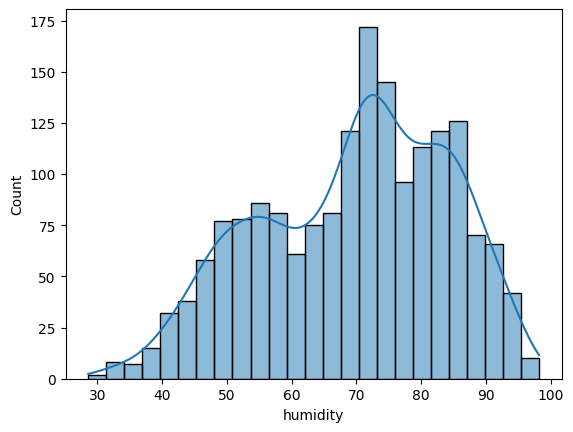

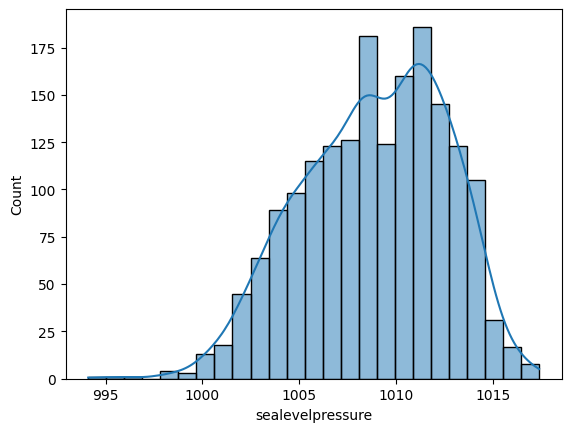

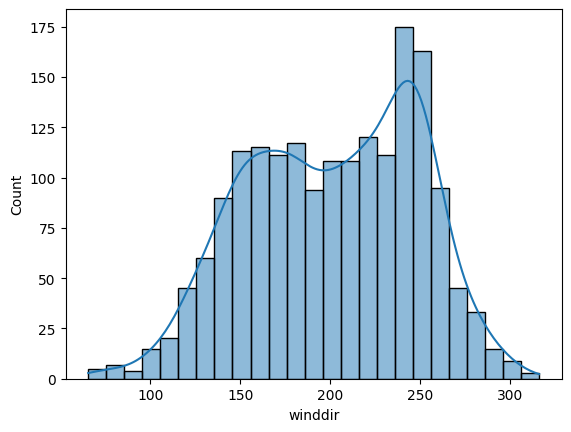

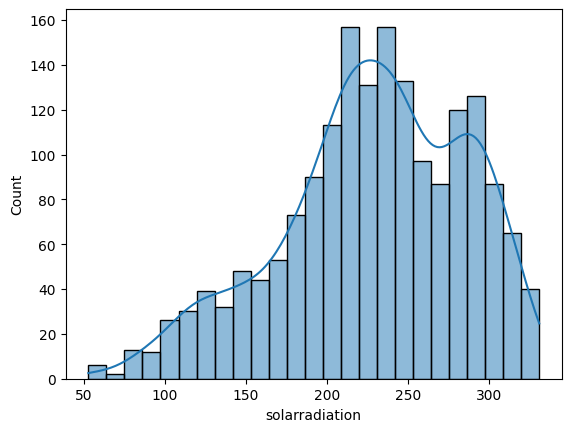

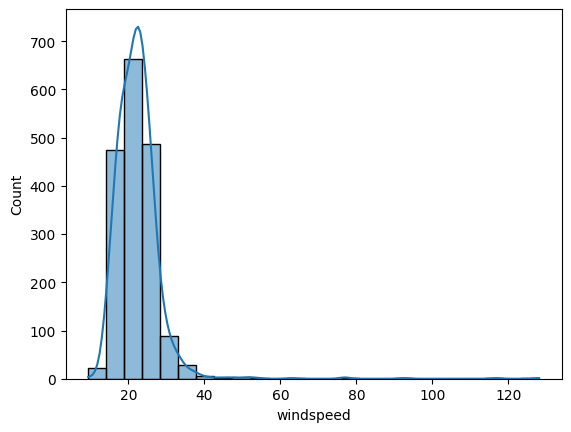

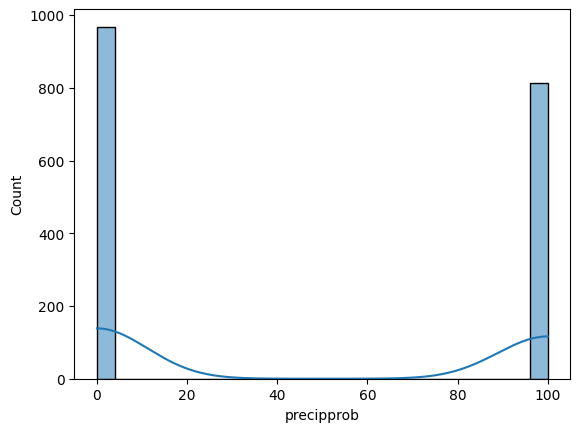

In [128]:
for i in num_cols:
    sns.histplot(df,x=i,bins=25,kde=True)
    plt.show()

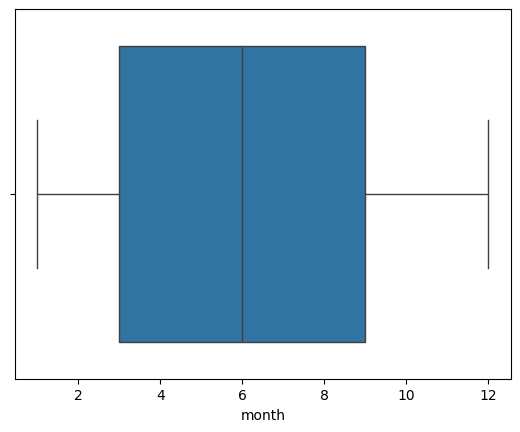

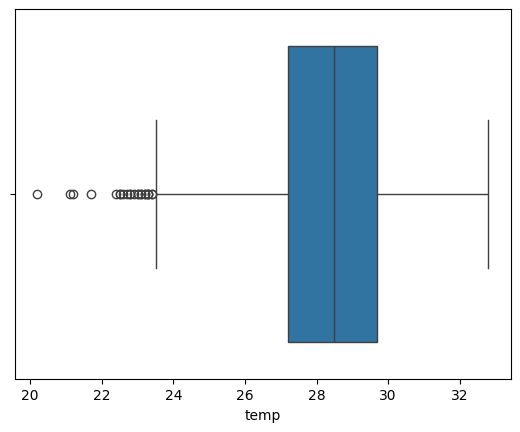

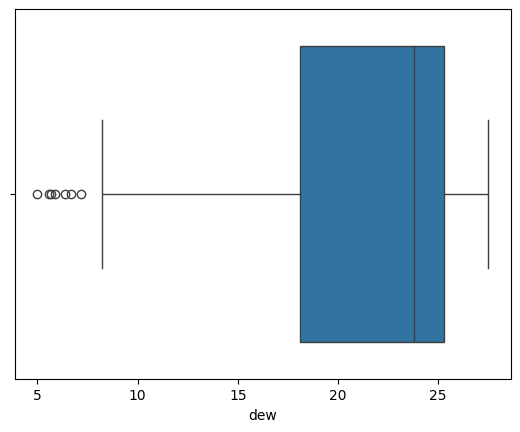

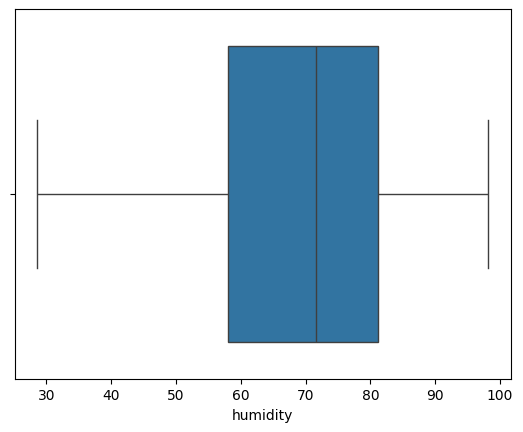

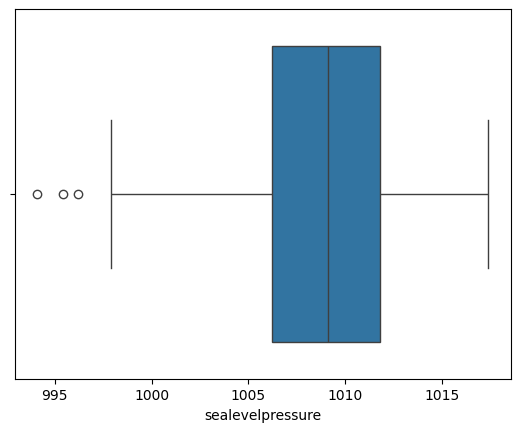

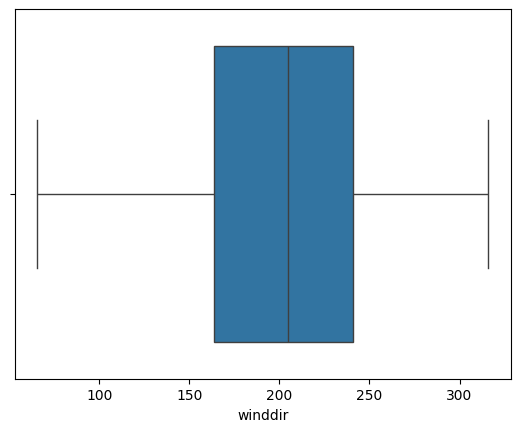

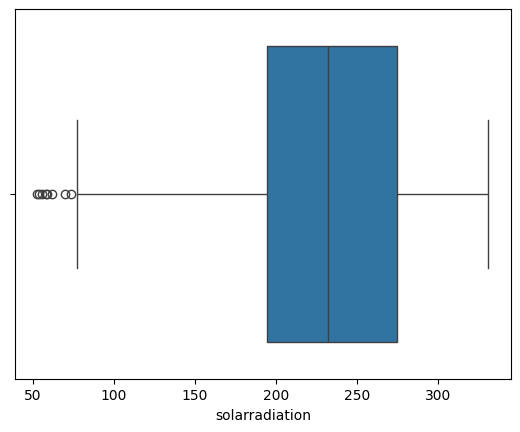

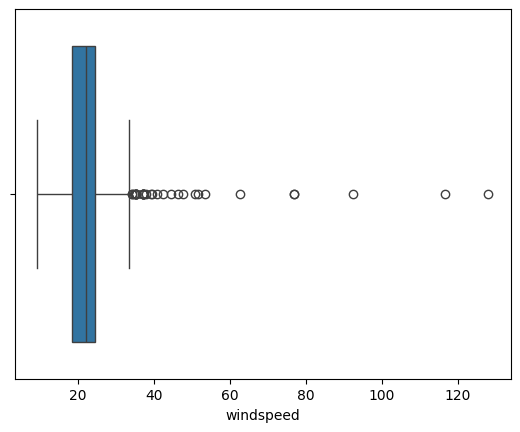

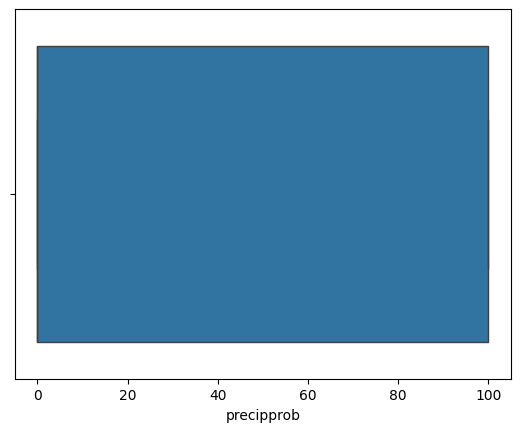

In [129]:
for i in num_cols:
    sns.boxplot(df,x=i)
    plt.show()

In [130]:
from sklearn.preprocessing import StandardScaler,PowerTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer

In [131]:
preprocessor = ColumnTransformer([
    ("num",Pipeline([
        ("impute",SimpleImputer(strategy="median")),
        ("skew",PowerTransformer(method="yeo-johnson")),
        ("scaler",StandardScaler())
    ]),num_cols)
])
preprocessor

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""{feature_na

In [132]:
X_train_pre = preprocessor.fit_transform(X_train)
X_test_pre = preprocessor.transform(X_test)

In [133]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, ExtraTreesClassifier ,AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from xgboost import XGBClassifier

In [144]:
results = []
models = {
    'Logistic Regression': LogisticRegression(class_weight="balanced"),
    'Decision Tree': DecisionTreeClassifier(random_state=42,class_weight="balanced"),
    'Random Forest': RandomForestClassifier(random_state=42, n_jobs=-1,class_weight="balanced"),
    'Extra Trees': ExtraTreesClassifier(random_state=42, n_jobs=-1,class_weight="balanced"),
    'Gradient Boosting': GradientBoostingClassifier(random_state=42),
    'K-Neighbors': KNeighborsClassifier(n_neighbors=20),
    'Support Vector Classifier': SVC(kernel='rbf',class_weight="balanced"),
    "XGBoost": XGBClassifier(random_state=42),
    "AdaBoost": AdaBoostClassifier(random_state=42),
}

In [145]:
for name,model in models.items():
    model.fit(X_train_pre,y_train)
    y_pred = model.predict(X_test_pre)
    Accuracy_score = accuracy_score(y_test,y_pred)
    F2_score = f1_score(y_test, y_pred)
    results.append({
        "Name":name,
        "Accuracy_score":Accuracy_score,
        "F2_score":F2_score
    })

results_df = pd.DataFrame(results)
results_df

,Name,Accuracy_score,F2_score
0,Logistic Regression,1.000000,1.000000
1,Decision Tree,1.000000,1.000000
2,Random Forest,1.000000,1.000000
3,Extra Trees,1.000000,1.000000
4,Gradient Boosting,1.000000,1.000000
5,K-Neighbors,0.988796,0.987578
6,Support Vector Classifier,1.000000,1.000000
7,XGBoost,1.000000,1.000000
8,AdaBoost,1.000000,1.000000


In [ ]:
model_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', KNeighborsClassifier(n_neighbors=20))
])
model_pipeline.fit(X_train, y_train)
y_pred = model_pipeline.predict(X_test)
Accuracy_score = accuracy_score(y_test,y_pred)
F2_score = f1_score(y_test, y_pred)
print(Accuracy_score)
print(F2_score)

0.988795518207283
0.9875776397515528


In [ ]:
import joblib

joblib.dump(model_pipeline, "model_pipeline.pkl")
joblib.dump(preprocessor, "preprocessor.pkl")

['preprocessor.pkl']